# Segmentation d'images, détection d'objets, segmentation sémantique et d'instance

Un **seul jeu d'images**, quatre méthodes, comparées côte à côte.

| # | Méthode | Question posée | Sortie |
|---|---|---|---|
| 1 | Segmentation classique (k-means, SLIC) | Quels pixels se ressemblent ? | Régions sans classe |
| 2 | Détection d'objets (Faster R-CNN) | Quoi et où ? | Boîtes + classe + score |
| 3 | Segmentation sémantique (DeepLabV3) | Quelle classe par pixel ? | Carte de classes |
| 4 | Segmentation d'instance (Mask R-CNN) | Quel objet, quels pixels ? | Un masque par objet |

La section 11 **mesure** chaque méthode avec des métriques standard (ASA, IoU, mAP, mIoU, Dice) contre les annotations COCO.

**Fonctionnement 100 % local** : les poids pré-entraînés (~160 Mo par modèle) sont téléchargés une seule fois par `torchvision`, puis stockés dans le cache (`~/.cache/torch`). Aucune API cloud. CPU suffisant (quelques secondes par image), GPU utilisé automatiquement s'il existe.

## 1. Installation

**Étapes de la cellule suivante**

1. Installer les bibliothèques (une seule fois).

In [1]:
# À exécuter une seule fois (décommentez la ligne)
# %pip install -q torch torchvision scikit-image scikit-learn matplotlib pillow pandas pycocotools

## 2. Imports communs

**Étapes de la cellule suivante**

1. Importer les bibliothèques communes à tout le notebook.

In [2]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams["figure.dpi"] = 110

## 3. Jeu de données commun

Toutes les méthodes travaillent sur **les mêmes images**, lues dans `data/images/`.

- Mettez-y vos propres images (`.jpg` / `.png`), par exemple la photo de rugby des exemples du cours.
- Si le dossier est vide, le notebook télécharge 4 images de COCO val2017 (`images.cocodataset.org`).

**Étapes de la cellule suivante**

1. Créer le dossier `data/images/` s'il n'existe pas.
2. Si le dossier est vide, télécharger 4 images COCO d'exemple.
3. Charger les images et les réduire (côté max 640 px) pour accélérer les calculs.

In [3]:
DATA_DIR = Path("data/images")
DATA_DIR.mkdir(parents=True, exist_ok=True)

COCO_IDS = ["000000000139", "000000000724", "000000000785", "000000001000"]
MAX_SIDE = 640     # on réduit les images pour accélérer les modèles
MAX_IMAGES = 4     # nombre d'images traitées


def list_images():
    exts = {".jpg", ".jpeg", ".png"}
    return sorted(p for p in DATA_DIR.iterdir() if p.suffix.lower() in exts)


def download_samples():
    for i in COCO_IDS:
        dest = DATA_DIR / f"coco_{i}.jpg"
        if not dest.exists():
            try:
                urllib.request.urlretrieve(f"http://images.cocodataset.org/val2017/{i}.jpg", dest)
            except Exception as e:
                print(f"Téléchargement impossible ({e}). Placez vos images dans {DATA_DIR}/")
                break


if not list_images():
    download_samples()

paths = list_images()[:MAX_IMAGES]
assert paths, f"Aucune image trouvée dans {DATA_DIR}/"


def load(path):
    img = Image.open(path).convert("RGB")
    img.thumbnail((MAX_SIDE, MAX_SIDE))
    return img


images = [load(p) for p in paths]
names = [p.stem for p in paths]
print(f"{len(images)} image(s) :", names)

4 image(s) : ['coco_000000000139', 'coco_000000000724', 'coco_000000000785', 'coco_000000001000']


**Étapes de la cellule suivante**

1. Définir une petite fonction d'affichage en grille, réutilisée partout.
2. Afficher les images d'origine.

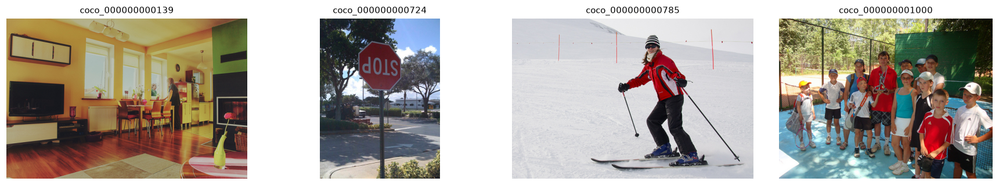

In [4]:
def show(imgs, titles=None, ncols=4, size=4):
    nrows = (len(imgs) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * 0.75 * nrows), squeeze=False)
    flat = axes.ravel()
    for ax in flat:
        ax.axis("off")
    for k, im in enumerate(imgs):
        flat[k].imshow(im)
        if titles:
            flat[k].set_title(titles[k], fontsize=10)
    plt.tight_layout()
    plt.show()


show(images, names)

## 4. Segmentation d'images classique

**Définition** : partitionner l'image en régions de pixels homogènes (couleur, texture). Aucune notion de classe : on ne sait pas *ce que* contient une région.

- **k-means sur la couleur** : chaque pixel prend la couleur de son centre de cluster.
- **SLIC (superpixels)** : régions compactes qui suivent les contours.

**Étapes de la cellule suivante**

1. **k-means** : regrouper les pixels en 5 couleurs dominantes.
2. **SLIC** : découper l'image en superpixels (régions compactes).
3. Appliquer les deux méthodes à toutes les images et afficher les résultats.

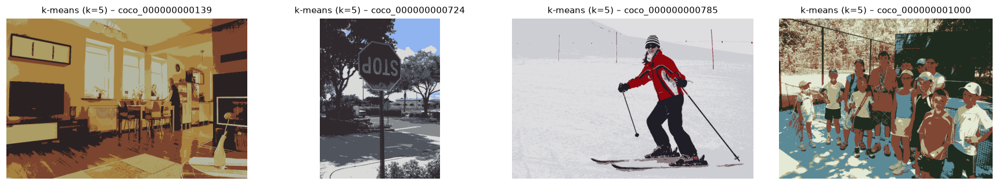

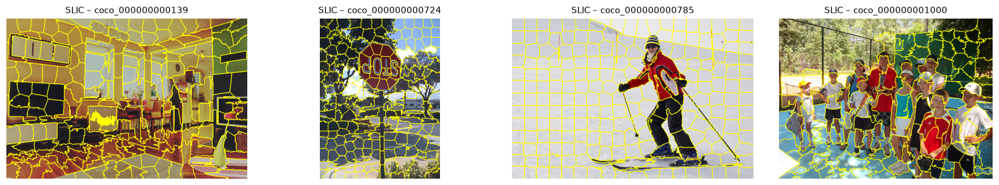

In [5]:
from sklearn.cluster import KMeans
from skimage.segmentation import slic, mark_boundaries


def seg_kmeans(img, k=5, n_fit=20000, seed=0):
    arr = np.asarray(img)
    pix = arr.reshape(-1, 3).astype(np.float32)
    rng = np.random.RandomState(seed)
    sample = pix[rng.choice(len(pix), min(n_fit, len(pix)), replace=False)]
    km = KMeans(n_clusters=k, n_init=3, random_state=seed).fit(sample)
    labels = km.predict(pix)
    return km.cluster_centers_.astype(np.uint8)[labels].reshape(arr.shape)


def seg_slic(img, n_segments=250):
    arr = np.asarray(img)
    labels = slic(arr, n_segments=n_segments, compactness=10, start_label=1)
    return labels, mark_boundaries(arr, labels)


kmeans_imgs = [seg_kmeans(im) for im in images]
slic_imgs = [seg_slic(im)[1] for im in images]

show(kmeans_imgs, [f"k-means (k=5) – {n}" for n in names])
show(slic_imgs, [f"SLIC – {n}" for n in names])

## 5. Préparation PyTorch

Les trois méthodes suivantes utilisent des réseaux pré-entraînés sur **COCO** (`torchvision`). Au premier appel, les poids sont téléchargés puis restent en cache local.

**Étapes de la cellule suivante**

1. Importer PyTorch et choisir le GPU s'il existe, sinon le CPU.

In [6]:
import torch
import torchvision.transforms.functional as TF
from torchvision.utils import draw_bounding_boxes, draw_segmentation_masks

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
print("Device :", device)

Device : cpu


## 6. Détection d'objets (Faster R-CNN)

**Définition** : localiser et classer les objets. Pour chaque objet : une **boîte englobante**, une **classe** et un **score de confiance**. Le contour exact n'est pas connu (la boîte inclut du fond).

**Étapes de la cellule suivante**

1. Charger Faster R-CNN pré-entraîné sur COCO (poids téléchargés une seule fois).
2. `detect()` : prédire les boîtes, ne garder que celles avec un score ≥ 0,6.
3. `draw_det()` : dessiner les boîtes avec la classe et le score.
4. Lancer sur toutes les images et lister les objets trouvés.

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to C:\Users\chaim/.cache\torch\hub\checkpoints\fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


0.1%

0.2%

0.2%

0.3%

0.4%

... (1,269 outputs left out)

99.8%

99.8%

99.9%

100.0%

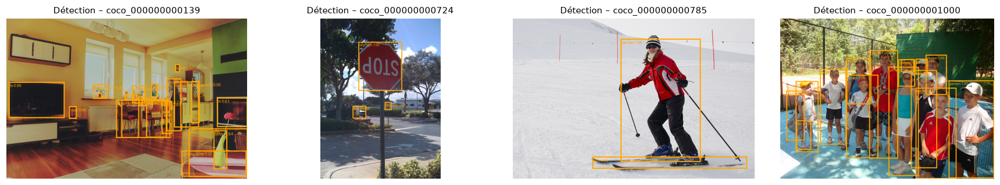

coco_000000000139 : chair (1.00), chair (0.99), tv (0.99), potted plant (0.98), person (0.98), clock (0.97), vase (0.96), vase (0.96), dining table (0.95), chair (0.93), potted plant (0.91), vase (0.90), refrigerator (0.90), refrigerator (0.88), vase (0.87), bottle (0.84), vase (0.82), person (0.78), dining table (0.71), vase (0.70), dining table (0.68), dining table (0.65), tv (0.61)
coco_000000000724 : stop sign (1.00), truck (0.99), stop sign (0.98)
coco_000000000785 : person (1.00), skis (0.95)
coco_000000001000 : person (1.00), person (1.00), person (1.00), person (1.00), person (1.00), person (1.00), person (0.99), person (0.99), person (0.95), handbag (0.93), tennis racket (0.83), person (0.72), person (0.71), person (0.63), person (0.62)


In [7]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights

det_weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
det_model = fasterrcnn_resnet50_fpn(weights=det_weights).eval().to(device)
COCO_CLASSES = det_weights.meta["categories"]


@torch.no_grad()
def detect(img, thr=0.6):
    out = det_model([TF.to_tensor(img).to(device)])[0]
    keep = out["scores"] >= thr
    return {k: v[keep].cpu() for k, v in out.items()}


def draw_det(img, res):
    labels = [f"{COCO_CLASSES[l]} {s:.2f}" for l, s in zip(res["labels"].tolist(), res["scores"].tolist())]
    out = draw_bounding_boxes(TF.pil_to_tensor(img), res["boxes"], labels=labels, colors="orange", width=3)
    return out.permute(1, 2, 0).numpy()


det_results = [detect(im) for im in images]
det_imgs = [draw_det(im, r) for im, r in zip(images, det_results)]
show(det_imgs, [f"Détection – {n}" for n in names])

for n, r in zip(names, det_results):
    found = [f"{COCO_CLASSES[l]} ({s:.2f})" for l, s in zip(r["labels"].tolist(), r["scores"].tolist())]
    print(f"{n} : {', '.join(found) if found else 'aucun objet'}")

## 7. Segmentation sémantique (DeepLabV3)

**Définition** : attribuer une **classe à chaque pixel** (ciel, arbre, personne, herbe…), sans distinguer les objets d'une même classe : deux personnes côte à côte forment une seule zone « person ».

Remarque : ce modèle prédit les 21 classes de Pascal VOC (fond + 20 objets), pas les classes « stuff » comme le ciel ou l'herbe. Ces zones tombent dans le fond (`background`).

**Étapes de la cellule suivante**

1. Charger DeepLabV3 pré-entraîné (21 classes Pascal VOC).
2. `segment_semantic()` : prédire une classe par pixel, puis reprendre la taille de l'image.
3. `overlay_semantic()` : superposer les couleurs de classes sur l'image.
4. Afficher les résultats et le pourcentage de pixels par classe.

0.1%

0.2%

0.2%

0.3%

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to C:\Users\chaim/.cache\torch\hub\checkpoints\deeplabv3_resnet50_coco-cd0a2569.pth


0.4%

... (1,276 outputs left out)

99.8%

99.9%

100.0%

100.0%

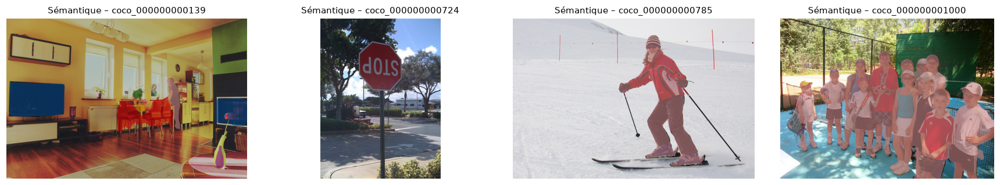

coco_000000000139 : bottle 0.3%, chair 3.0%, diningtable 0.2%, person 0.9%, pottedplant 0.2%, tvmonitor 6.7%
coco_000000000724 : fond uniquement
coco_000000000785 : person 10.5%
coco_000000001000 : person 42.4%


In [8]:
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights

sem_weights = DeepLabV3_ResNet50_Weights.DEFAULT
sem_model = deeplabv3_resnet50(weights=sem_weights).eval().to(device)
sem_prep = sem_weights.transforms()
VOC_CLASSES = sem_weights.meta["categories"]


def voc_cmap(n=256):
    # Palette standard Pascal VOC
    cmap = np.zeros((n, 3), dtype=np.uint8)
    for i in range(n):
        r = g = b = 0
        c = i
        for j in range(8):
            r |= ((c >> 0) & 1) << (7 - j)
            g |= ((c >> 1) & 1) << (7 - j)
            b |= ((c >> 2) & 1) << (7 - j)
            c >>= 3
        cmap[i] = (r, g, b)
    return cmap


VOC_CMAP = voc_cmap()


@torch.no_grad()
def segment_semantic(img):
    x = sem_prep(img).unsqueeze(0).to(device)
    out = sem_model(x)["out"]
    out = torch.nn.functional.interpolate(out, size=(img.height, img.width), mode="bilinear", align_corners=False)
    return out.argmax(1)[0].cpu()          # tenseur [H, W] d'indices de classes


def overlay_semantic(img, mask, alpha=0.6):
    color = VOC_CMAP[mask.numpy()]
    base = np.asarray(img).astype(np.float32)
    out = np.where((mask.numpy() > 0)[..., None], (1 - alpha) * base + alpha * color, base)
    return out.astype(np.uint8)


sem_results = [segment_semantic(im) for im in images]
sem_imgs = [overlay_semantic(im, m) for im, m in zip(images, sem_results)]
show(sem_imgs, [f"Sémantique – {n}" for n in names])

for n, m in zip(names, sem_results):
    ids, counts = np.unique(m.numpy(), return_counts=True)
    parts = [f"{VOC_CLASSES[i]} {100 * c / m.numel():.1f}%" for i, c in zip(ids, counts) if i > 0]
    print(f"{n} : {', '.join(parts) if parts else 'fond uniquement'}")

## 8. Segmentation d'instance (Mask R-CNN)

**Définition** : détecter chaque objet **et** délimiter son contour au pixel près : un **masque distinct par individu**. Contrairement à la sémantique, on peut compter et suivre chaque objet.

**Étapes de la cellule suivante**

1. Charger Mask R-CNN pré-entraîné sur COCO.
2. `segment_instance()` : prédire un masque par objet (score ≥ 0,6).
3. `draw_inst()` : colorier chaque masque d'une couleur différente, avec sa boîte.
4. Afficher les résultats et compter les instances.

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to C:\Users\chaim/.cache\torch\hub\checkpoints\maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


0.1%

0.1%

0.2%

0.3%

0.4%

... (1,350 outputs left out)

99.8%

99.9%

99.9%

100.0%

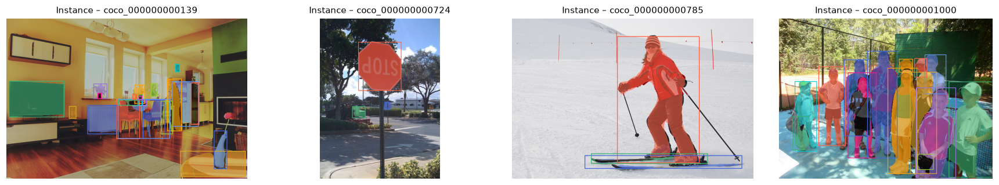

coco_000000000139 : 23 instance(s)
coco_000000000724 : 3 instance(s)
coco_000000000785 : 3 instance(s)
coco_000000001000 : 14 instance(s)


In [9]:
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights

inst_weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
inst_model = maskrcnn_resnet50_fpn(weights=inst_weights).eval().to(device)
INST_PALETTE = [(255, 99, 71), (65, 105, 225), (60, 179, 113), (255, 165, 0), (147, 112, 219),
                (0, 206, 209), (255, 20, 147), (218, 165, 32), (100, 149, 237), (154, 205, 50)]


@torch.no_grad()
def segment_instance(img, thr=0.6):
    out = inst_model([TF.to_tensor(img).to(device)])[0]
    keep = out["scores"] >= thr
    return {
        "masks": (out["masks"][keep, 0] > 0.5).cpu(),      # [N, H, W] booléens
        "boxes": out["boxes"][keep].cpu(),
        "labels": out["labels"][keep].cpu(),
        "scores": out["scores"][keep].cpu(),
    }


def draw_inst(img, res):
    base = TF.pil_to_tensor(img)
    if len(res["masks"]) == 0:
        return base.permute(1, 2, 0).numpy()
    colors = [INST_PALETTE[i % len(INST_PALETTE)] for i in range(len(res["masks"]))]
    out = draw_segmentation_masks(base, res["masks"], alpha=0.6, colors=colors)
    out = draw_bounding_boxes(out, res["boxes"], colors=colors, width=2)
    return out.permute(1, 2, 0).numpy()


inst_results = [segment_instance(im) for im in images]
inst_imgs = [draw_inst(im, r) for im, r in zip(images, inst_results)]
show(inst_imgs, [f"Instance – {n}" for n in names])

for n, r in zip(names, inst_results):
    print(f"{n} : {len(r['masks'])} instance(s)")

## 9. Comparaison des quatre méthodes sur les mêmes images

Colonnes : image d'origine, segmentation classique (SLIC), détection, sémantique, instance.

**Étapes de la cellule suivante**

1. Assembler dans une même grille : original, SLIC, détection, sémantique, instance.
2. Enregistrer la figure dans `outputs/comparaison.png`.

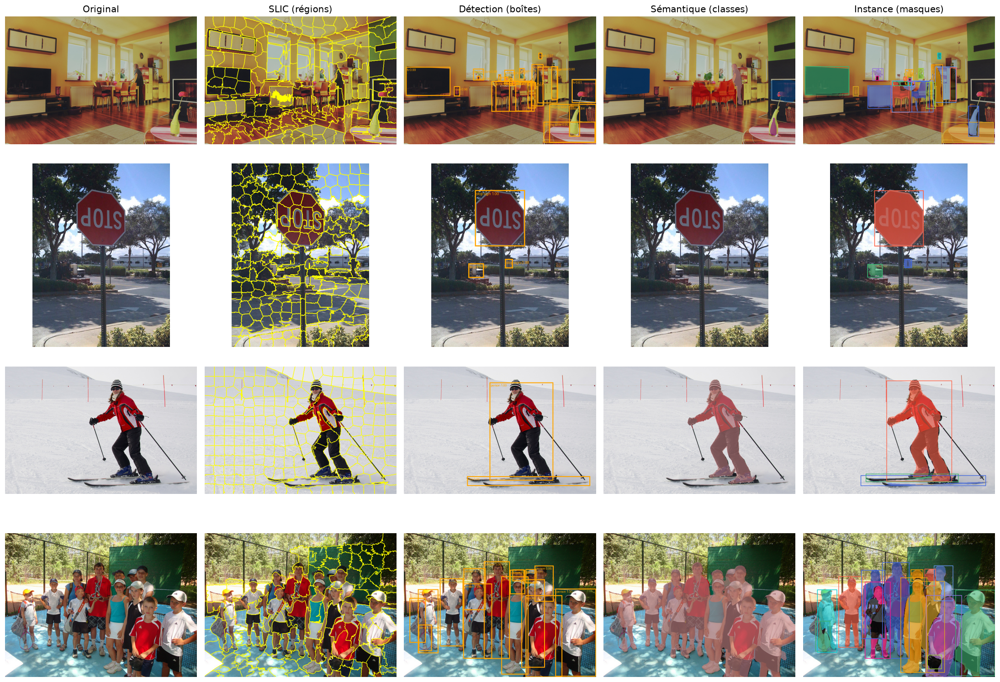

In [10]:
cols = ["Original", "SLIC (régions)", "Détection (boîtes)", "Sémantique (classes)", "Instance (masques)"]
rows = [images, slic_imgs, det_imgs, sem_imgs, inst_imgs]

fig, axes = plt.subplots(len(images), 5, figsize=(20, 3.6 * len(images)), squeeze=False)
for i in range(len(images)):
    for j in range(5):
        ax = axes[i, j]
        ax.imshow(rows[j][i])
        ax.axis("off")
        if i == 0:
            ax.set_title(cols[j], fontsize=13)
plt.tight_layout()

Path("outputs").mkdir(exist_ok=True)
fig.savefig("outputs/comparaison.png", dpi=130, bbox_inches="tight")
plt.show()

## 10. Cohérence entre méthodes (sans vérité terrain)

On compare ce que chaque méthode dit de la classe **person** :

- nombre de personnes vu par la **détection** et par l'**instance**,
- part des pixels « person » vue par la **sémantique**,
- **IoU** entre le masque sémantique « person » et l'union des masques d'instance « person ».

L'IoU (intersection sur union) vaut 1 si les deux méthodes marquent exactement les mêmes pixels.

**Étapes de la cellule suivante**

1. Définir l'IoU : surface commune / surface réunie de deux masques.
2. Pour chaque image : compter les personnes (détection, instance) et le % de pixels « person » (sémantique).
3. Calculer l'IoU entre le masque sémantique et l'union des masques d'instance.

In [11]:
PERSON_COCO = COCO_CLASSES.index("person")
PERSON_VOC = VOC_CLASSES.index("person")


def iou(a, b):
    a, b = a.bool(), b.bool()
    union = (a | b).sum().item()
    return (a & b).sum().item() / union if union else float("nan")


records = []
for n, im, d, s, r in zip(names, images, det_results, sem_results, inst_results):
    sem_person = s == PERSON_VOC
    person_masks = r["masks"][r["labels"] == PERSON_COCO]
    inst_person = person_masks.any(dim=0) if len(person_masks) else torch.zeros_like(sem_person)
    records.append({
        "image": n,
        "personnes (détection)": int((d["labels"] == PERSON_COCO).sum()),
        "personnes (instance)": int((r["labels"] == PERSON_COCO).sum()),
        "% pixels person (sémantique)": round(100 * sem_person.float().mean().item(), 1),
        "IoU sémantique / instance": round(iou(sem_person, inst_person), 2),
    })

pd.DataFrame(records)

,image,personnes (détection),personnes (instance),% pixels person (sémantique),IoU sémantique / instance
0,coco_000000000139,2,2,0.9,0.70
1,coco_000000000724,0,0,0.0,NaN
2,coco_000000000785,1,1,10.5,0.89
3,coco_000000001000,13,12,42.4,0.90


## 11. Métriques d'évaluation (avec vérité terrain COCO)

Jusqu'ici on a comparé les méthodes visuellement. Ici on les **mesure** contre les annotations humaines de COCO.

| Méthode | Métriques | Définition |
|---|---|---|
| Segmentation classique (SLIC) | **ASA**, rappel de frontières | ASA : part des pixels bien rangés si chaque superpixel prend le segment réel majoritaire. Rappel : part des contours réels retrouvés (tolérance 2 px). |
| Détection | **IoU**, **AP / mAP** | IoU = surface commune / surface réunie de la boîte prédite et de la boîte réelle. AP = aire sous la courbe précision-rappel ; mAP = moyenne sur les classes, pour des seuils d'IoU de 0,5 à 0,95. |
| Sémantique | **IoU par classe, mIoU, Dice** | mIoU = moyenne des IoU par classe. Dice = 2·\|A∩B\| / (\|A\|+\|B\|). |
| Instance | **mAP des masques** | Comme la détection, mais l'IoU est calculé sur les **masques**. |

Conditions : la vérité terrain existe pour les images **COCO** (fichiers `coco_<id>.jpg`). Votre image de rugby n'a pas d'annotations : elle est ignorée ici. Avec seulement 4 images, les chiffres sont **indicatifs** ; augmentez `MAX_IMAGES` pour plus de fiabilité.

### 11.1 Chargement de la vérité terrain

Le fichier d'annotations COCO (`annotations_trainval2017.zip`, ~241 Mo) est téléchargé **une seule fois**, on n'en garde que `instances_val2017.json`.

**Étapes de la cellule suivante**

1. Télécharger les annotations COCO (une seule fois) et en extraire `instances_val2017.json`.
2. Repérer les images évaluables (nommées `coco_<id>.jpg`).
3. Charger la vérité terrain avec `pycocotools`.

In [12]:
import json
import zipfile
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_utils

ANN_DIR = Path("data/annotations")
ANN_DIR.mkdir(parents=True, exist_ok=True)
ANN_FILE = ANN_DIR / "instances_val2017.json"

if not ANN_FILE.exists():
    try:
        zip_path = ANN_DIR / "annotations_trainval2017.zip"
        print("Téléchargement des annotations COCO (~241 Mo, une seule fois)...")
        urllib.request.urlretrieve("http://images.cocodataset.org/annotations/annotations_trainval2017.zip", zip_path)
        with zipfile.ZipFile(zip_path) as z, z.open("annotations/instances_val2017.json") as src:
            ANN_FILE.write_bytes(src.read())
        zip_path.unlink()
    except Exception as e:
        print(f"Annotations indisponibles ({e}).")

# Images évaluables : fichiers nommés coco_<id>.jpg
eval_items = [(k, int(n.split("_")[1])) for k, n in enumerate(names) if n.startswith("coco_")]
HAS_GT = ANN_FILE.exists() and len(eval_items) > 0

if HAS_GT:
    coco_gt = COCO(str(ANN_FILE))
    img_ids = [i for _, i in eval_items]
    print(f"Évaluation sur {len(eval_items)} image(s) COCO :", img_ids)
else:
    print("Pas de vérité terrain disponible : sautez les cellules 11.x (les images doivent s'appeler coco_<id>.jpg).")

Téléchargement des annotations COCO (~241 Mo, une seule fois)...


loading annotations into memory...


Done (t=0.52s)
creating index...
index created!
Évaluation sur 4 image(s) COCO : [139, 724, 785, 1000]


### 11.2 Outils : redimensionnement, vérité terrain sémantique et d'instance

On convertit les annotations COCO en cartes de pixels. Pour la sémantique, seules les 20 classes de Pascal VOC sont gardées (celles du modèle) ; les autres objets COCO comptent comme fond.

**Étapes de la cellule suivante**

1. Faire correspondre les noms de classes COCO et Pascal VOC.
2. `resize_mask()` : redimensionner une carte d'entiers sans interpoler les valeurs.
3. `gt_semantic()` / `gt_instances_map()` : transformer les annotations COCO en cartes de pixels.

In [13]:
COCO_TO_VOC = {
    "airplane": "aeroplane", "bicycle": "bicycle", "bird": "bird", "boat": "boat", "bottle": "bottle",
    "bus": "bus", "car": "car", "cat": "cat", "chair": "chair", "cow": "cow", "dining table": "diningtable",
    "dog": "dog", "horse": "horse", "motorcycle": "motorbike", "person": "person",
    "potted plant": "pottedplant", "sheep": "sheep", "couch": "sofa", "train": "train", "tv": "tvmonitor",
}


def gt_size(img_id):
    info = coco_gt.imgs[img_id]
    return info["width"], info["height"]          # (largeur, hauteur) de l'image d'origine


def resize_mask(m, size):
    # Redimensionnement « plus proche voisin » d'une carte d'entiers vers size = (largeur, hauteur)
    w, h = size
    H, W = m.shape[:2]
    ys = np.minimum((np.arange(h) * H / h).astype(int), H - 1)
    xs = np.minimum((np.arange(w) * W / w).astype(int), W - 1)
    return m[ys][:, xs]


def gt_semantic(img_id):
    # Carte de classes VOC (0 = fond) construite à partir des annotations COCO
    cat_to_voc = {c["id"]: VOC_CLASSES.index(COCO_TO_VOC[c["name"]])
                  for c in coco_gt.loadCats(coco_gt.getCatIds()) if c["name"] in COCO_TO_VOC}
    W, H = gt_size(img_id)
    gt = np.zeros((H, W), dtype=np.int64)
    for a in coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_id)):
        if a["category_id"] in cat_to_voc:
            gt[coco_gt.annToMask(a) > 0] = cat_to_voc[a["category_id"]]
    return gt


def gt_instances_map(img_id):
    # Carte où chaque objet annoté (toutes classes) a un identifiant propre (0 = fond)
    W, H = gt_size(img_id)
    gt = np.zeros((H, W), dtype=np.int64)
    for k, a in enumerate(coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_id)), start=1):
        gt[coco_gt.annToMask(a) > 0] = k
    return gt

### 11.3 Segmentation classique : ASA et rappel de frontières (SLIC)

Les superpixels n'ont pas de classe : on les juge sur leur capacité à **respecter les contours réels** des objets annotés.

**Étapes de la cellule suivante**

1. `asa()` : chaque superpixel reçoit le segment réel majoritaire, puis on mesure la précision.
2. `boundary_recall()` : part des contours réels retrouvés à ± 2 pixels.
3. Calculer ces deux scores sur les images COCO.

In [14]:
from skimage.segmentation import find_boundaries
from scipy.ndimage import binary_dilation


def asa(labels, gt):
    # Achievable Segmentation Accuracy : chaque superpixel reçoit le segment réel majoritaire
    total = 0
    for sp in np.unique(labels):
        total += np.bincount(gt[labels == sp]).max()
    return total / labels.size


def boundary_recall(labels, gt, tol=2):
    # Part des frontières réelles situées à moins de `tol` pixels d'une frontière de superpixel
    gt_b = find_boundaries(gt, mode="inner")
    sp_b = binary_dilation(find_boundaries(labels, mode="inner"), iterations=tol)
    return (gt_b & sp_b).sum() / max(gt_b.sum(), 1)


slic_scores = {"ASA": [], "Rappel de frontières": []}
if HAS_GT:
    for k, img_id in eval_items:
        im = images[k]
        gt = resize_mask(gt_instances_map(img_id), (im.width, im.height))
        labels, _ = seg_slic(im)
        slic_scores["ASA"].append(asa(labels, gt))
        slic_scores["Rappel de frontières"].append(boundary_recall(labels, gt))
    for name, vals in slic_scores.items():
        print(f"SLIC – {name} (moyenne) : {np.mean(vals):.3f}")

SLIC – ASA (moyenne) : 0.937
SLIC – Rappel de frontières (moyenne) : 0.605


### 11.4 Détection : IoU des boîtes et mAP

L'**IoU** mesure le recouvrement d'une boîte prédite avec la boîte réelle. Le **mAP** (calculé par `pycocotools`, comme dans la compétition COCO) résume la qualité sur tous les seuils de confiance et d'IoU.

Pour le mAP, on garde toutes les détections à partir d'un score de 0,05 (et non 0,6) afin de tracer la courbe précision-rappel.

**Étapes de la cellule suivante**

1. `box_iou_np()` : IoU entre boîtes prédites et boîtes réelles.
2. `run_coco_eval()` : lancer l'évaluation officielle COCO (mAP).
3. Convertir les prédictions au format COCO (boîtes et masques) à seuil bas (0,05).
4. Calculer le mAP des boîtes, l'IoU moyen, puis le mAP des masques.

In [15]:
def box_iou_np(a, b):
    # IoU entre toutes les paires de boîtes a [N,4] et b [M,4] au format (x1, y1, x2, y2)
    a, b = np.asarray(a, dtype=float).reshape(-1, 4), np.asarray(b, dtype=float).reshape(-1, 4)
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def run_coco_eval(results, iou_type):
    if not results:
        return [0.0] * 12
    ev = COCOeval(coco_gt, coco_gt.loadRes(results), iou_type)
    ev.params.imgIds = img_ids
    ev.evaluate()
    ev.accumulate()
    ev.summarize()
    return ev.stats          # stats[0] = AP@[.5:.95], stats[1] = AP50, stats[2] = AP75


det_json, inst_json = [], []
box_ious, box_recalls = [], []

if HAS_GT:
    for k, img_id in eval_items:
        im = images[k]
        W, H = gt_size(img_id)
        sx, sy = W / im.width, H / im.height          # ramener les prédictions à la taille d'origine

        # --- détection à seuil bas, pour le mAP
        d = detect(im, thr=0.05)
        for (x1, y1, x2, y2), l, s in zip(d["boxes"].tolist(), d["labels"].tolist(), d["scores"].tolist()):
            det_json.append({"image_id": img_id, "category_id": l, "score": s,
                             "bbox": [x1 * sx, y1 * sy, (x2 - x1) * sx, (y2 - y1) * sy]})

        # --- instance à seuil bas, pour le mAP des masques
        r = segment_instance(im, thr=0.05)
        for m, l, s in zip(r["masks"], r["labels"].tolist(), r["scores"].tolist()):
            full = resize_mask(m.numpy().astype(np.uint8), (W, H))
            rle = mask_utils.encode(np.asfortranarray(full))
            rle["counts"] = rle["counts"].decode("ascii")
            inst_json.append({"image_id": img_id, "category_id": l, "score": s, "segmentation": rle})

        # --- IoU moyen des boîtes (seuil 0,6) : meilleure boîte prédite de même classe pour chaque objet réel
        gt_anns = [a for a in coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_id)) if a["iscrowd"] == 0]
        pred = det_results[k]
        pred_boxes = pred["boxes"].numpy() * np.array([sx, sy, sx, sy])
        for a in gt_anns:
            x, y, w, h = a["bbox"]
            same = pred["labels"].numpy() == a["category_id"]
            best = box_iou_np([[x, y, x + w, y + h]], pred_boxes[same]).max() if same.any() else 0.0
            box_ious.append(best)
            box_recalls.append(best >= 0.5)

    print("=== Détection : mAP des boîtes ===")
    det_stats = run_coco_eval(det_json, "bbox")
    print(f"\nIoU moyen des boîtes : {np.mean(box_ious):.3f} | rappel à IoU ≥ 0,5 : {np.mean(box_recalls):.3f}")

    print("\n=== Instance : mAP des masques ===")
    inst_stats = run_coco_eval(inst_json, "segm")

=== Détection : mAP des boîtes ===
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.02s).
Accumulating evaluation results...
DONE (t=0.07s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.460
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.677
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.536
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.367
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.647
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.928
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.315
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.516
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.523
 Average Recall     (AR) @[ IoU=0

### 11.5 Segmentation sémantique : IoU par classe, mIoU et Dice

On accumule une **matrice de confusion** (classe réelle × classe prédite) sur tous les pixels des images évaluées.

Pour une classe : IoU = TP / (TP + FP + FN) et Dice = 2·TP / (2·TP + FP + FN). Le **mIoU** et le **Dice moyen** sont les moyennes sur les classes présentes (dans la vérité terrain ou dans la prédiction).

**Étapes de la cellule suivante**

1. Construire la matrice de confusion (classe réelle × classe prédite) sur tous les pixels.
2. En déduire IoU et Dice par classe, puis mIoU, Dice moyen et précision pixel.

In [16]:
def confusion(gt, pred, n):
    idx = n * gt.ravel() + pred.ravel()
    return np.bincount(idx, minlength=n * n).reshape(n, n)       # lignes = réel, colonnes = prédit


n_cls = len(VOC_CLASSES)
conf = np.zeros((n_cls, n_cls), dtype=np.int64)

if HAS_GT:
    for k, img_id in eval_items:
        pred = resize_mask(sem_results[k].numpy().astype(np.int64), gt_size(img_id))
        conf += confusion(gt_semantic(img_id), pred, n_cls)

    tp = np.diag(conf).astype(float)
    fp = conf.sum(axis=0) - tp
    fn = conf.sum(axis=1) - tp
    present = (tp + fp + fn) > 0
    iou_c = np.where(present, tp / np.maximum(tp + fp + fn, 1), np.nan)
    dice_c = np.where(present, 2 * tp / np.maximum(2 * tp + fp + fn, 1), np.nan)
    miou, mdice, pix_acc = np.nanmean(iou_c), np.nanmean(dice_c), tp.sum() / conf.sum()

    print(f"mIoU = {miou:.3f} | Dice moyen = {mdice:.3f} | précision pixel = {pix_acc:.3f}")
    pd.DataFrame({"classe": VOC_CLASSES, "IoU": iou_c.round(3), "Dice": dice_c.round(3)}).dropna().reset_index(drop=True)

mIoU = 0.431 | Dice moyen = 0.483 | précision pixel = 0.971


### 11.6 Récapitulatif des métriques

Segmentation classique, détection, sémantique et instance, mesurées sur les mêmes images avec la même vérité terrain.

**Étapes de la cellule suivante**

1. Rassembler toutes les métriques dans un seul tableau.
2. Enregistrer le tableau (`metriques.csv`) et le graphique (`metriques.png`).

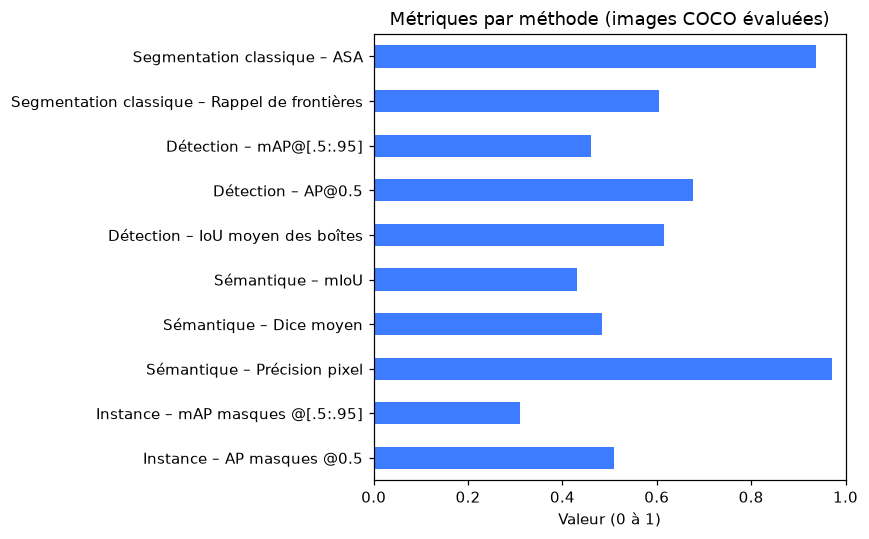

,Méthode,Métrique,Valeur
0,Segmentation classique (SLIC),ASA,0.937
1,Segmentation classique (SLIC),Rappel de frontières,0.605
2,Détection (Faster R-CNN),mAP@[.5:.95],0.460
3,Détection (Faster R-CNN),AP@0.5,0.677
4,Détection (Faster R-CNN),IoU moyen des boîtes,0.615
5,Sémantique (DeepLabV3),mIoU,0.431
6,Sémantique (DeepLabV3),Dice moyen,0.483
7,Sémantique (DeepLabV3),Précision pixel,0.971
8,Instance (Mask R-CNN),mAP masques @[.5:.95],0.311
9,Instance (Mask R-CNN),AP masques @0.5,0.510


In [17]:
if HAS_GT:
    summary = pd.DataFrame([
        ("Segmentation classique (SLIC)", "ASA", np.mean(slic_scores["ASA"])),
        ("Segmentation classique (SLIC)", "Rappel de frontières", np.mean(slic_scores["Rappel de frontières"])),
        ("Détection (Faster R-CNN)", "mAP@[.5:.95]", det_stats[0]),
        ("Détection (Faster R-CNN)", "AP@0.5", det_stats[1]),
        ("Détection (Faster R-CNN)", "IoU moyen des boîtes", np.mean(box_ious)),
        ("Sémantique (DeepLabV3)", "mIoU", miou),
        ("Sémantique (DeepLabV3)", "Dice moyen", mdice),
        ("Sémantique (DeepLabV3)", "Précision pixel", pix_acc),
        ("Instance (Mask R-CNN)", "mAP masques @[.5:.95]", inst_stats[0]),
        ("Instance (Mask R-CNN)", "AP masques @0.5", inst_stats[1]),
    ], columns=["Méthode", "Métrique", "Valeur"])
    summary["Valeur"] = summary["Valeur"].astype(float).round(3)

    Path("outputs").mkdir(exist_ok=True)
    summary.to_csv("outputs/metriques.csv", index=False)

    ax = summary.assign(label=summary["Méthode"].str.split(" \\(").str[0] + " – " + summary["Métrique"]) \
                .set_index("label")["Valeur"].iloc[::-1].plot.barh(figsize=(8, 5), color="#3D7BFF")
    ax.set_xlim(0, 1)
    ax.set_xlabel("Valeur (0 à 1)")
    ax.set_ylabel("")
    ax.set_title("Métriques par méthode (images COCO évaluées)")
    plt.tight_layout()
    plt.savefig("outputs/metriques.png", dpi=130)
    plt.show()

summary if HAS_GT else None

## 12. À retenir

| Méthode | Granularité | Distingue les individus ? | Donne la classe ? |
|---|---|---|---|
| Segmentation classique | Région de pixels | Non | Non |
| Détection | Boîte | Oui | Oui |
| Sémantique | Pixel | Non | Oui |
| Instance | Pixel | Oui | Oui |

### Aller plus loin
- Évaluer sur COCO avec `pycocotools` (mAP pour la détection, mIoU pour la sémantique).
- Remplacer Faster R-CNN par YOLO (`ultralytics`, exécutable en local) pour la détection et l'instance.
- Fine-tuner un modèle sur vos propres images annotées.